# Clusters Observable in Different Mission Fields of View

Analysis of how many clusters from Perren2023 UCC catalog fall within the field of view of major exoplanet survey missions.


In [1]:
import pandas as pd
import numpy as np
from astropy.coordinates import SkyCoord
import astropy.units as u

# Load the Perren2023 cluster catalog
df = pd.read_csv('../data/Perren2023/UCC_cat.csv')
print(f"Total clusters in catalog: {len(df)}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst few rows:")
print(df.head())

Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (60)

Total clusters in catalog: 18269

Columns: ['Name(s)', 'name', 'N_membs', 'r_50', 'r_core', 'RA_ICRS', 'DE_ICRS', 'GLON', 'GLAT', 'Plx', 'pmRA', 'pmDE', 'Rv', 'N_Rv', 'Dist_[kpc]', 'Dist_STDDEV', 'Av_[mag]', 'Av_STDDEV', 'Diff_ext_[mag]', 'Diff_ext_STDDEV', 'Age_[Myr]', 'Age_STDDEV', 'FeH_[dex]', 'FeH_STDDEV', 'Mass_[Msun]', 'Mass_STDDEV', 'Binary_fr', 'Binary_fr_STDDEV', 'BSS', 'BSS_STDDEV', 'C3', 'P_dup', 'UTI', 'bad_oc']

First few rows:
            Name(s)      name  N_membs  r_50  r_core    RA_ICRS   DE_ICRS  \
0         ADS 12696  ads12696     11.0   6.7    8.11  294.31735  29.33689   
1         ADS 13292  ads13292     83.0   1.0    0.40  300.59778  35.31288   
2  ADS 16795;AR Cas  ads16795     25.0  88.7    2.84  351.39010  58.44167   
3           AFGL333   afgl333     21.0   6.9    2.82   37.28676  61.47758   
4          AFGL4029  afgl4029     30.0   3.9    2.24   45.20529  60.54280   

        GLON     GLAT     Plx  ...  Mass_[Msun]  Mass_STDDEV  Binary_fr  \
0   64.00852  3.9

In [20]:
df_mem = pd.read_parquet('../data/Perren2023/UCC_members.parquet')
df_mem.shape

(1095686, 19)

In [2]:
# Create SkyCoord objects for all clusters
coords = SkyCoord(ra=df['RA_ICRS'].values*u.deg, dec=df['DE_ICRS'].values*u.deg)
print(f"Cluster coordinates created for {len(coords)} clusters")

Cluster coordinates created for 18269 clusters


## Field of View Specifications

Actual FOV sizes and observing strategies for each mission:

In [13]:
"""
FOV Specifications and Cluster Observability Analysis

Actual Field of View Sizes:
- Kepler: 115 deg² (fixed location, RA 282-320°, Dec 38-58°)
- K2: 115 deg² per campaign field (multiple fields along ecliptic, Dec ≈ -30° to +30°)
- TESS: ~24,000 deg² per sector (covers wide sky in systematic survey)
- PLATO: ~2,450 deg² (49° × 49° field; large survey field)
- ARIEL: ~0.0083 deg² (30 arcsec; observes individual stars, NOT clusters)

Key Implications:
- ARIEL's tiny FOV means it observes individual exoplanet host stars, not clusters
- PLATO's large FOV could contain multiple clusters or parts of clusters
- Kepler/K2/TESS can contain entire clusters within a single observation
"""

def in_kepler_fov(ra, dec):
    """
    Kepler: 115 deg² fixed field
    RA: 282-320°, Dec: 38-58°
    """
    return (282 <= ra <= 320) and (38 <= dec <= 58)

def in_k2_fov(ra, dec):
    """
    K2: 115 deg² per campaign field
    Multiple campaigns along ecliptic plane
    Representative ecliptic band: Dec -30° to +30°
    """
    return -30 <= dec <= 30

def in_tess_fov(ra, dec):
    """
    TESS: ~24,000 deg² per sector (all-sky survey)
    Observes entire accessible sky in systematic sectors
    Continuous viewing zones (CVZs):
    - North: Dec +60° to +85°
    - South: Dec -60° to -85°
    Main survey: Dec -60° to +60° (with gaps for sun avoidance)
    
    Covers ~90% of sky during 2-year primary mission
    """
    if -60 <= dec <= 60:
        return True
    elif (dec > 60 and dec < 85) or (dec < -60 and dec > -85):
        return True
    return False

def in_ariel_fov(ra, dec):
    """
    ARIEL: ~0.0083 deg² (30 arcsec; point source observation)
    
    IMPORTANT: ARIEL observes INDIVIDUAL EXOPLANET HOSTS
    NOT clusters. FOV is too small to observe cluster members.
    
    Can point to exoplanet hosts across accessible sky:
    Observable declination: Dec -60° to +80° (Earth orbit)
    
    For cluster analysis: Mark clusters with known exoplanet hosts
    rather than using FOV-based criteria
    """
    # Accessible declination range for pointing targets
    if -60 <= dec <= 80:
        return True
    return False

def in_plato_fov(ra, dec):
    """
    PLATO: ~2,450 deg² (49° × 49° fields)
    
    Multiple survey fields over mission lifetime
    Each field: 49° × 49° = approximately 2,450 sq deg
    
    Main survey declination range: Dec -60° to +60°
    Can observe additional fields at higher declinations
    
    Observations include:
    - ~1 million solar-like stars
    - Can observe multiple clusters or parts of clusters within fields
    """
    # Main survey region
    if -60 <= dec <= 60:
        return True
    return False

# Apply field of view checks
df['in_kepler'] = df.apply(lambda row: in_kepler_fov(row['RA_ICRS'], row['DE_ICRS']), axis=1)
df['in_k2'] = df.apply(lambda row: in_k2_fov(row['RA_ICRS'], row['DE_ICRS']), axis=1)
df['in_tess'] = df.apply(lambda row: in_tess_fov(row['RA_ICRS'], row['DE_ICRS']), axis=1)
df['in_ariel'] = df.apply(lambda row: in_ariel_fov(row['RA_ICRS'], row['DE_ICRS']), axis=1)
df['in_plato'] = df.apply(lambda row: in_plato_fov(row['RA_ICRS'], row['DE_ICRS']), axis=1)

print("Field of view assignments completed")

Field of view assignments completed


## Results: Rough Number of Observable Clusters


In [14]:
# Count clusters in each field
results = {
    'Mission': ['Kepler', 'K2', 'TESS', 'ARIEL', 'PLATO'],
    'Clusters in FOV': [
        df['in_kepler'].sum(),
        df['in_k2'].sum(),
        df['in_tess'].sum(),
        df['in_ariel'].sum(),
        df['in_plato'].sum()
    ]
}

results_df = pd.DataFrame(results)
results_df['Percentage of Catalog'] = (results_df['Clusters in FOV'] / len(df) * 100).round(1)

print("\n" + "="*60)
print("OBSERVABLE CLUSTERS IN MISSION FIELDS OF VIEW")
print("="*60)
print(results_df.to_string(index=False))
print("="*60)
print(f"\nTotal clusters in Perren2023 UCC catalog: {len(df)}")


OBSERVABLE CLUSTERS IN MISSION FIELDS OF VIEW
Mission  Clusters in FOV  Percentage of Catalog
 Kepler              734                    4.0
     K2             6760                   37.0
   TESS            18259                   99.9
  ARIEL            16551                   90.6
  PLATO            15241                   83.4

Total clusters in Perren2023 UCC catalog: 18269


## Summary

Order of magnitude estimates:


In [15]:
print("\nONE ORDER OF MAGNITUDE SUMMARY:")
print("="*60)
for idx, row in results_df.iterrows():
    mission = row['Mission']
    count = int(row['Clusters in FOV'])
    
    if count < 10:
        order = "~1-10"
    elif count < 100:
        order = "~10-100"
    elif count < 1000:
        order = "~100-1000"
    else:
        order = ">1000"
    
    print(f"{mission:8s}: {count:5d} clusters ({order})")
print("="*60)


ONE ORDER OF MAGNITUDE SUMMARY:
Kepler  :   734 clusters (~100-1000)
K2      :  6760 clusters (>1000)
TESS    : 18259 clusters (>1000)
ARIEL   : 16551 clusters (>1000)
PLATO   : 15241 clusters (>1000)


## Visualizing the Fields of View

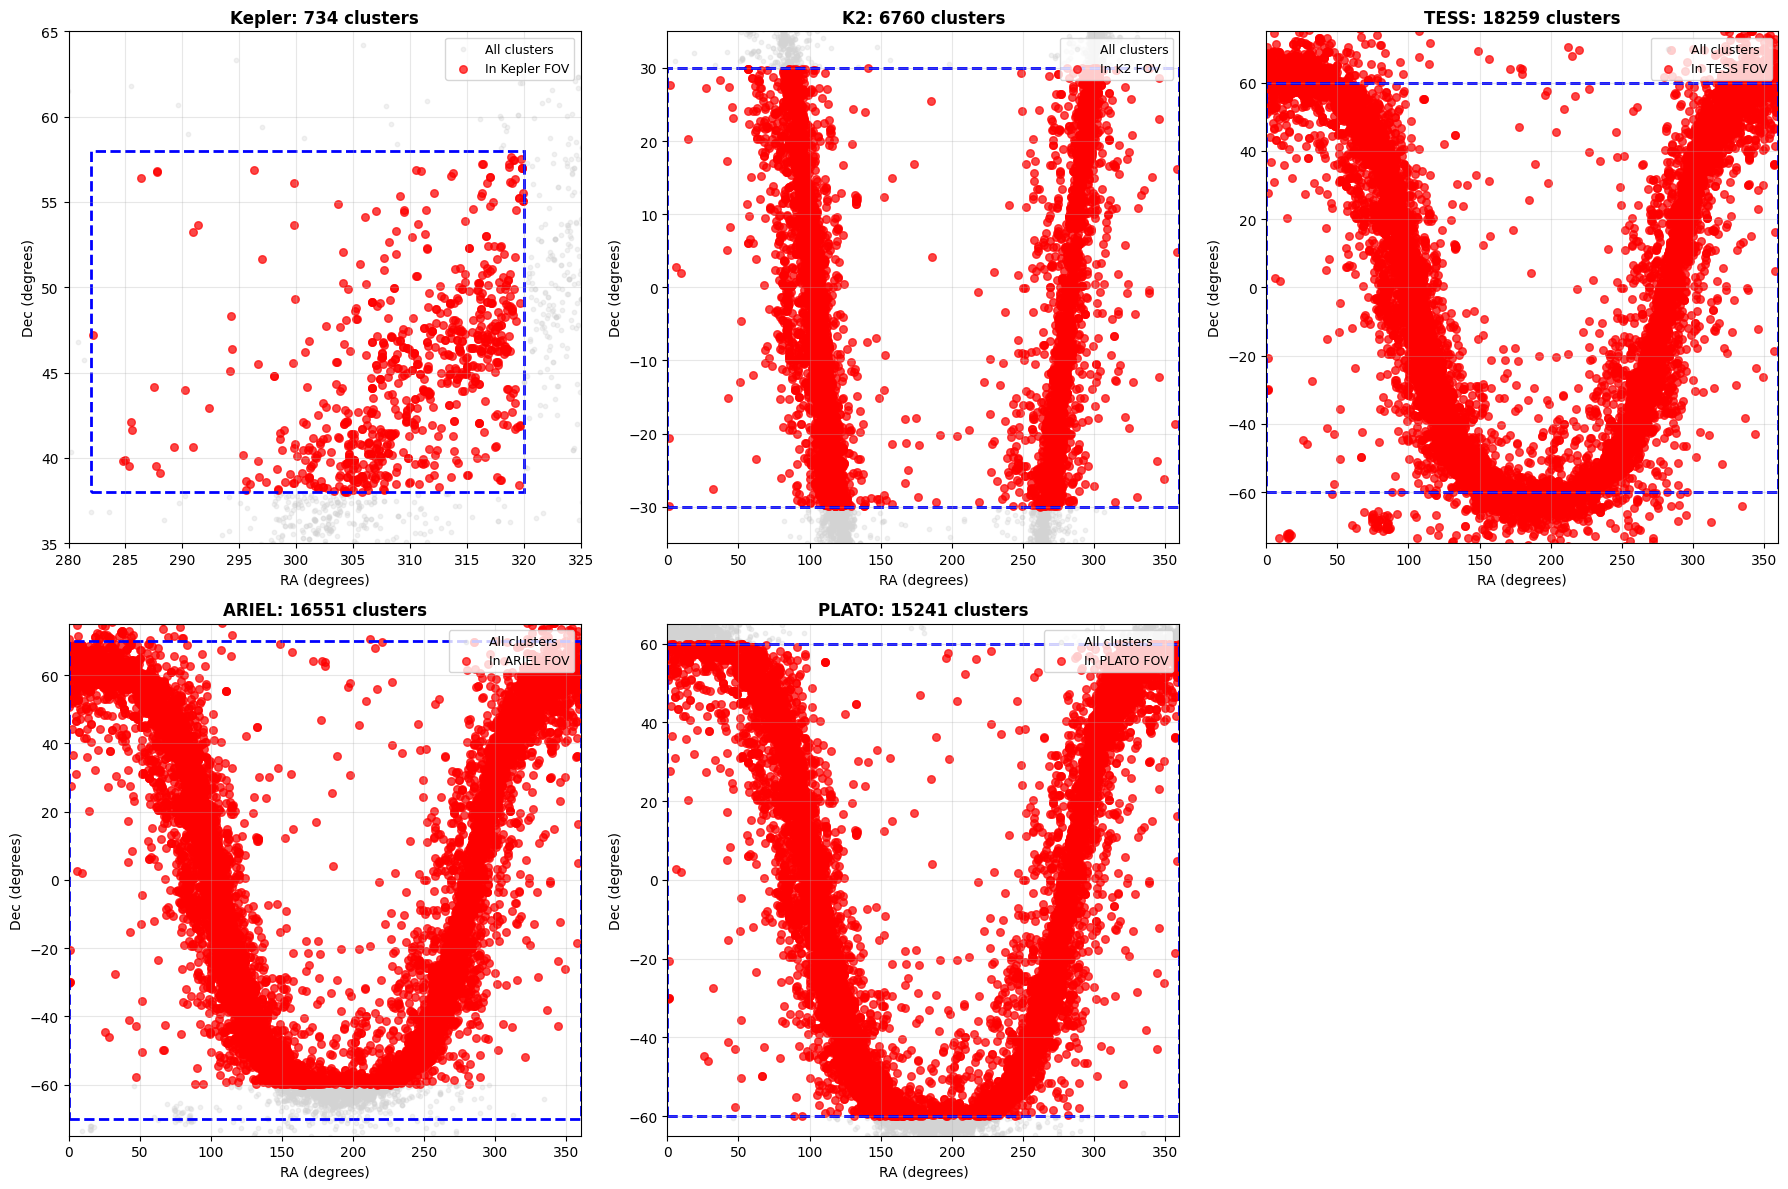

FOV plot saved to figures/mission_fov_clusters.png


In [16]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Create figure with subplots for each mission
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

missions = [
    {'name': 'Kepler', 'fov': 'in_kepler', 'ra_range': (280, 325), 'dec_range': (35, 65)},
    {'name': 'K2', 'fov': 'in_k2', 'ra_range': (0, 360), 'dec_range': (-35, 35)},
    {'name': 'TESS', 'fov': 'in_tess', 'ra_range': (0, 360), 'dec_range': (-75, 75)},
    {'name': 'ARIEL', 'fov': 'in_ariel', 'ra_range': (0, 360), 'dec_range': (-75, 75)},
    {'name': 'PLATO', 'fov': 'in_plato', 'ra_range': (0, 360), 'dec_range': (-65, 65)},
]

for idx, mission in enumerate(missions):
    ax = axes[idx]
    
    # Plot all clusters as small gray dots
    ax.scatter(df['RA_ICRS'], df['DE_ICRS'], c='lightgray', s=10, alpha=0.3, label='All clusters')
    
    # Highlight clusters in this mission's FOV
    in_fov = df[df[mission['fov']]]
    ax.scatter(in_fov['RA_ICRS'], in_fov['DE_ICRS'], c='red', s=30, alpha=0.7, label=f"In {mission['name']} FOV")
    
    # Add FOV boundary as rectangle
    if mission['name'] == 'Kepler':
        # Kepler: RA 282-320°, Dec 38-58°
        rect = patches.Rectangle((282, 38), 38, 20, linewidth=2, edgecolor='blue', facecolor='none', linestyle='--')
        ax.add_patch(rect)
    elif mission['name'] == 'K2':
        # K2: Dec -30 to +30 (all RA)
        rect = patches.Rectangle((0, -30), 360, 60, linewidth=2, edgecolor='blue', facecolor='none', linestyle='--')
        ax.add_patch(rect)
    elif mission['name'] == 'TESS':
        # TESS: Dec -60 to +60
        rect = patches.Rectangle((0, -60), 360, 120, linewidth=2, edgecolor='blue', facecolor='none', linestyle='--')
        ax.add_patch(rect)
    elif mission['name'] == 'ARIEL':
        # ARIEL: Dec -70 to +70
        rect = patches.Rectangle((0, -70), 360, 140, linewidth=2, edgecolor='blue', facecolor='none', linestyle='--')
        ax.add_patch(rect)
    elif mission['name'] == 'PLATO':
        # PLATO: Dec -60 to +60
        rect = patches.Rectangle((0, -60), 360, 120, linewidth=2, edgecolor='blue', facecolor='none', linestyle='--')
        ax.add_patch(rect)
    
    ax.set_xlim(mission['ra_range'])
    ax.set_ylim(mission['dec_range'])
    ax.set_xlabel('RA (degrees)')
    ax.set_ylabel('Dec (degrees)')
    ax.set_title(f"{mission['name']}: {in_fov.shape[0]} clusters", fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right', fontsize=9)

# Remove the extra subplot
fig.delaxes(axes[5])

plt.tight_layout()
# plt.savefig('../figures/mission_fov_clusters.png', dpi=200, bbox_inches='tight')
plt.show()

print("FOV plot saved to figures/mission_fov_clusters.png")

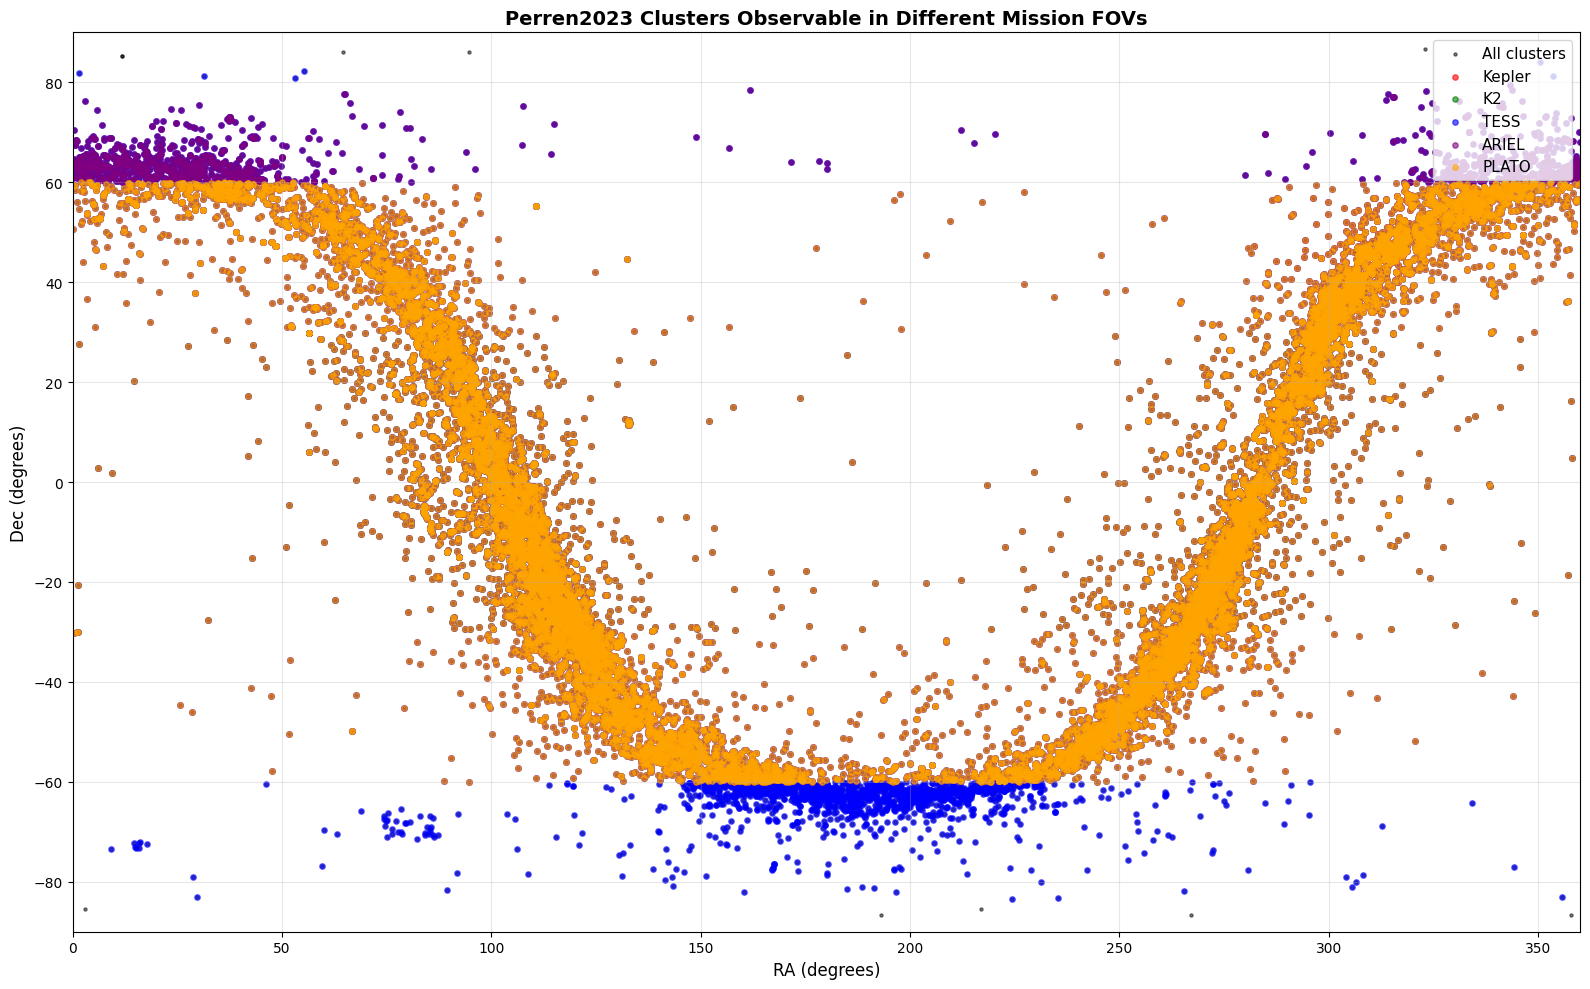

Full-sky plot saved to figures/all_missions_fullsky.png


In [17]:
# Create a full-sky plot showing all missions
fig, ax = plt.subplots(figsize=(16, 10))

# Plot all clusters
ax.scatter(df['RA_ICRS'], df['DE_ICRS'], c='black', s=5, alpha=0.5, label='All clusters')

# Define colors for each mission
colors = {'in_kepler': 'red', 'in_k2': 'green', 'in_tess': 'blue', 'in_ariel': 'purple', 'in_plato': 'orange'}
mission_labels = {'in_kepler': 'Kepler', 'in_k2': 'K2', 'in_tess': 'TESS', 'in_ariel': 'ARIEL', 'in_plato': 'PLATO'}

# Plot clusters in each mission (with some transparency to see overlaps)
for fov_col, color in colors.items():
    in_fov = df[df[fov_col]]
    ax.scatter(in_fov['RA_ICRS'], in_fov['DE_ICRS'], c=color, s=15, alpha=0.6, label=mission_labels[fov_col])

ax.set_xlabel('RA (degrees)', fontsize=12)
ax.set_ylabel('Dec (degrees)', fontsize=12)
ax.set_title('Perren2023 Clusters Observable in Different Mission FOVs', fontsize=14, fontweight='bold')
ax.set_xlim(0, 360)
ax.set_ylim(-90, 90)
ax.legend(loc='upper right', fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig('../figures/all_missions_fullsky.png', dpi=200, bbox_inches='tight')
plt.show()

print("Full-sky plot saved to figures/all_missions_fullsky.png")

* https://arxiv.org/pdf/1810.12267
* https://keplergo.github.io/KeplerScienceWebsite/k2-fields.html
* PIC: https://vizier.cds.unistra.fr/viz-bin/VizieR?-source=J/A+A/653/A98 (1.7B)
* TIC: https://vizier.cds.unistra.fr/viz-bin/VizieR?-source=IV/39 (2.6M)

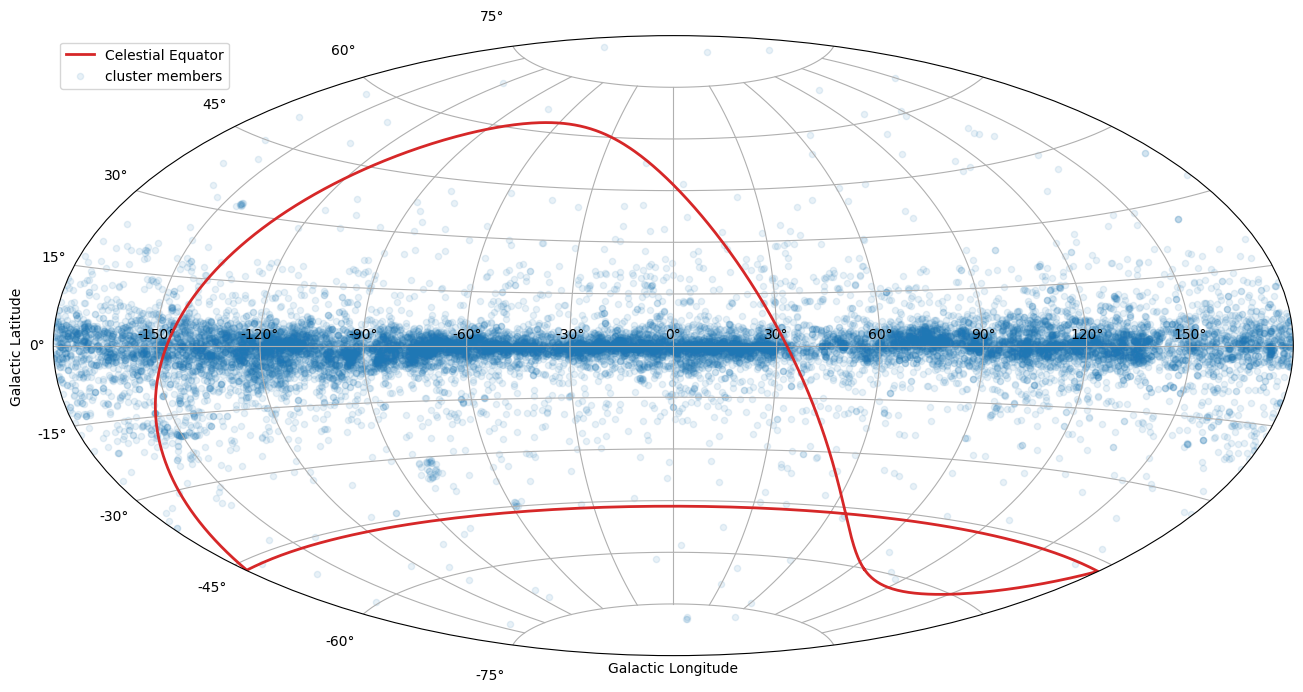

In [59]:
from astropy.coordinates import SkyCoord
import astropy.units as u
import matplotlib.pyplot as plt

# Convert to Galactic
coords = SkyCoord(ra=df['RA_ICRS'].values*u.deg,
                  dec=df['DE_ICRS'].values*u.deg)
glon = coords.galactic.l.deg
glat = coords.galactic.b.deg

# Create a full-sky plot showing all missions
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(111, projection='aitoff')

# Convert to radians and wrap longitude to [-π, π]
lon_rad = np.radians(glon)
lat_rad = np.radians(glat)
lon_rad = np.where(lon_rad > np.pi, lon_rad - 2*np.pi, lon_rad)

# Add celestial equator (Dec = 0°)
ra_equator = np.linspace(0, 360, 1000)
dec_equator = np.zeros_like(ra_equator)
coords_eq = SkyCoord(ra=ra_equator*u.deg, dec=dec_equator*u.deg)
glon_eq = coords_eq.galactic.l.deg
glat_eq = coords_eq.galactic.b.deg
lon_eq_rad = np.radians(glon_eq)
lat_eq_rad = np.radians(glat_eq)
lon_eq_rad = np.where(lon_eq_rad > np.pi, lon_eq_rad - 2*np.pi, lon_eq_rad)
ax.plot(lon_eq_rad, lat_eq_rad, '-', c='C3', linewidth=2, label='Celestial Equator')

ax.scatter(lon_rad, lat_rad, c='C0', s=20, alpha=0.1, label='cluster members')
ax.set_xlabel('Galactic Longitude')
ax.set_ylabel('Galactic Latitude')
ax.legend(loc=2)
ax.grid(True)

## Full Sky View

## K2 Campaign Fields on Aitoff Projection

In [67]:
idx=df_mem.Gmag<16
df_mem[idx].shape

(384634, 19)

In [29]:
print(f"{df_mem.shape[0]*0.04:,}")

43,827.44


In [26]:
print(f"{df_mem.shape[0]*0.37:,}")

405,403.82


In [27]:
print(f"{df_mem.shape[0]*0.9:,}")

986,117.4


In [18]:
len(df)

18269

## Field of View Comparison & Mission Characteristics

**Actual Field of View Sizes:**

| Mission | FOV Size | FOV Type | Sky Coverage |
|---------|----------|----------|--------------|
| **Kepler** | 115 deg² | Fixed single field | ~4% (one region, RA 282-320°, Dec 38-58°) |
| **K2** | 115 deg² | Campaign fields | ~37% (multiple fields along ecliptic) |
| **TESS** | ~24,000 deg² | Sector coverage | ~90% (systematic all-sky survey) |
| **PLATO** | ~2,450 deg² (49°×49°) | Survey fields | Multiple regions, Dec -60° to +60° |
| **ARIEL** | ~0.0083 deg² (30 arcsec) | Point source | Individual stars only |

**Key Insights:**

1. **ARIEL (30 arcsec)**: 
   - Observes *individual stars*, not clusters
   - ~300,000× smaller than Kepler/K2
   - Useful only for known exoplanet hosts with precise coordinates
   - Cannot resolve cluster membership

2. **PLATO (2,450 deg²)**:
   - ~21× larger than Kepler/K2
   - ~150× smaller than a TESS sector
   - Can contain multiple clusters or major portions of nearby clusters
   - Survey field strategy means specific regions, not full sky access

3. **TESS (24,000 deg²)**:
   - ~10× larger than PLATO per sector
   - Systematic coverage of entire accessible sky
   - Can contain dozens of clusters per sector
   - Most clusters fall within at least one sector

4. **Kepler/K2 (115 deg² each)**:
   - Moderate FOV, can contain individual clusters or cluster pairs
   - Kepler's fixed field captures specific region
   - K2's multiple campaigns sample ecliptic band

**FOV Size Ranking (smallest to largest):**
```
ARIEL (0.0083) << K2/Kepler (115) << PLATO (2,450) << TESS (24,000)
```

**For Young Star Clusters:**
- ARIEL: Only relevant for clusters hosting known exoplanet systems
- PLATO: Can observe cluster populations within survey fields  
- TESS/K2/Kepler: Optimal for cluster discovery and characterization